In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

In [3]:
#import micropip
#await micropip.install("seaborn")

In [4]:
#import seaborn as sns
#print(sns.__version__)

In [5]:
df = pd.read_csv("uber.csv")

print(df.head())
print(df.shape)

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

In [6]:
# Remove missing values
df = df.dropna()

# Remove unnecessary columns
df = df.drop(['Unnamed: 0', 'key'], axis=1)

# Remove invalid values
df = df[(df.fare_amount > 0) & (df.passenger_count > 0)]

print(df.head())
print(df.isnull().sum())

   fare_amount          pickup_datetime  pickup_longitude  pickup_latitude  \
0          7.5  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1          7.7  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2         12.9  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3          5.3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4         16.0  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         -73.965316         40.803349                3  
4         -73.973082         40.761247                5  
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64


In [7]:
# Convert datetime
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'], utc=True)

# Extract time features
df['hour'] = df['pickup_datetime'].dt.hour
df['day'] = df['pickup_datetime'].dt.day
df['month'] = df['pickup_datetime'].dt.month

# Calculate distance
lat1 = np.radians(df['pickup_latitude'])
lon1 = np.radians(df['pickup_longitude'])
lat2 = np.radians(df['dropoff_latitude'])
lon2 = np.radians(df['dropoff_longitude'])

a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2

df['distance'] = 6371 * 2 * np.arcsin(np.sqrt(a))

print(df[['distance', 'hour', 'day', 'month']].head())

   distance  hour  day  month
0  1.683323    19    7      5
1  2.457590    20   17      7
2  5.036377    21   24      8
3  1.661683     8   26      6
4  4.475450    17   28      8


In [8]:
# Handle outliers using IQR
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df['fare_amount'] = df['fare_amount'].clip(lower, upper)

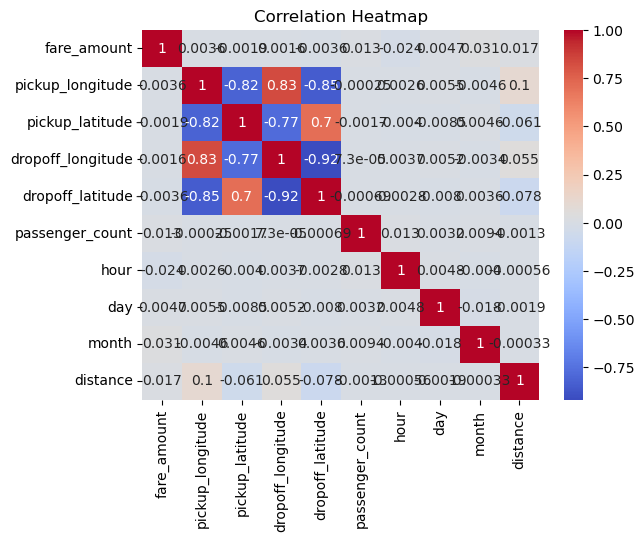

In [9]:
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')

plt.title("Correlation Heatmap")
plt.show()

In [10]:
X = df.drop(['fare_amount', 'pickup_datetime'], axis=1)

y = df['fare_amount']

print("Input features:", X.columns.tolist())
print("Target variable:", y.name)

Input features: ['pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'passenger_count', 'hour', 'day', 'month', 'distance']
Target variable: fare_amount


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (159415, 9)
Testing data: (39854, 9)


In [12]:
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': make_pipeline(StandardScaler(), Ridge()),
    'Lasso Regression': make_pipeline(StandardScaler(), Lasso())
}

In [13]:
for name, model in models.items():

    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    print("\n", name)
    print("R2 Score:", r2_score(y_test, pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))
    print("MAE:", mean_absolute_error(y_test, pred))


 Linear Regression
R2 Score: 0.001318224148338376
RMSE: 5.431586918787414
MAE: 4.340701611151919

 Ridge Regression
R2 Score: 0.0013183251718901223
RMSE: 5.431586644066162
MAE: 4.340701530616896

 Lasso Regression
R2 Score: -1.7998936763241602e-07
RMSE: 5.435170975792649
MAE: 4.343749893665528
